# Facebook Live Sellers in Thailand: Clustering

Unsupervised segmentation of Facebook posts from Thai fashion and cosmetics sellers, based on their engagement.

| | |
|---|---|
| **Task** | Clustering (unsupervised) |
| **Data** | UCI dataset #488: 7,050 posts from 10 retail seller pages (4,288 photos, 2,334 videos, 365 statuses, 63 links) |
| **Model** | K-Means on standardized features, visualized with PCA (2D and 3D) |
| **Result** | Best silhouette at **K = 2 (≈ 0.58)**; the final model uses K = 3 (≈ 0.30) |

## Approach
- Label-encoded `status_type`, split the publish timestamp into year / month / day / hour / minute, and standardized all 15 features.
- Searched K = 2…19 using both the elbow method and the silhouette score.
- Fitted K-Means with K = 3 and projected the clusters to 2D and 3D with PCA.

## Results

| K | Silhouette |
|---|---|
| 2 | ≈ 0.58 |
| 3 | ≈ 0.30 |
| 4-19 | ≈ 0.15-0.19 |

(Values read from the plot below.) Only K = 2 gives clearly separated clusters, and the elbow curve has no sharp bend.

![Elbow and silhouette](images/elbow_silhouette.png)
![PCA of the K=3 clusters](images/kmeans_pca_2d.png)

## Limitations & next steps
- The final model uses K = 3 although the silhouette score favors K = 2. The reason for that choice isn't documented in the notebook and should be added.
- Date parts such as year and minute are probably noise as numeric features, and label-encoded `status_type` implies an order that doesn't exist (one-hot encoding would be cleaner).
- Engagement counts are heavy-tailed, so a few viral posts likely dominate the distances. A log transform or robust scaling is worth testing.
- The clusters aren't profiled. Next step: average reactions / shares / post type per cluster to say what each group actually represents.


In [33]:
!pip install ucimlrepo

In [34]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy

In [35]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
facebook_live_sellers_in_thailand = fetch_ucirepo(id=488)

# data (as pandas dataframes)
X = facebook_live_sellers_in_thailand.data.features
y = facebook_live_sellers_in_thailand.data.targets

# metadata
print(facebook_live_sellers_in_thailand.metadata)

# variable information
print(facebook_live_sellers_in_thailand.variables)


{'uci_id': 488, 'name': 'Facebook Live Sellers in Thailand', 'repository_url': 'https://archive.ics.uci.edu/dataset/488/facebook+live+sellers+in+thailand', 'data_url': 'https://archive.ics.uci.edu/static/public/488/data.csv', 'abstract': 'Facebook pages of 10 Thai fashion and cosmetics retail sellers. Posts of a different nature (video, photos, statuses, and links). Engagement metrics consist of comments, shares, and reactions.', 'area': 'Business', 'tasks': ['Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 7051, 'num_features': 11, 'feature_types': ['Integer'], 'demographics': [], 'target_col': None, 'index_col': ['status_id'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2018, 'last_updated': 'Fri Mar 29 2024', 'dataset_doi': '10.24432/C5R60S', 'creators': ['Nassim Dehouche'], 'intro_paper': {'ID': 454, 'type': 'NATIVE', 'title': 'Dataset on usage and engagement patterns for Facebook Live sellers in Thailand', 'authors': '

In [36]:
df = pd.concat([X,y],axis=1)
df

,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0
1,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0
2,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0
3,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0
4,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
7045,photo,9/24/2016 2:58,89,0,0,89,0,0,0,0,0
7046,photo,9/23/2016 11:19,16,0,0,14,1,0,1,0,0
7047,photo,9/21/2016 23:03,2,0,0,1,1,0,0,0,0
7048,photo,9/20/2016 0:43,351,12,22,349,2,0,0,0,0


In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   status_type       7050 non-null   object
 1   status_published  7050 non-null   object
 2   num_reactions     7050 non-null   int64 
 3   num_comments      7050 non-null   int64 
 4   num_shares        7050 non-null   int64 
 5   num_likes         7050 non-null   int64 
 6   num_loves         7050 non-null   int64 
 7   num_wows          7050 non-null   int64 
 8   num_hahas         7050 non-null   int64 
 9   num_sads          7050 non-null   int64 
 10  num_angrys        7050 non-null   int64 
dtypes: int64(9), object(2)
memory usage: 606.0+ KB


In [38]:
df['status_type'].value_counts()

,count
status_type,
photo,4288
video,2334
status,365
link,63


In [39]:
le = LabelEncoder()
df['status_type'] = le.fit_transform(df['status_type'])
df['status_type'].value_counts()

,count
status_type,
1,4288
3,2334
2,365
0,63


In [40]:
df['status_published year'] = pd.to_datetime(df['status_published']).dt.year
df['status_published month'] = pd.to_datetime(df['status_published']).dt.month
df['status_published day'] = pd.to_datetime(df['status_published']).dt.day
df['status_published hour'] = pd.to_datetime(df['status_published']).dt.hour
df['status_published minute'] = pd.to_datetime(df['status_published']).dt.minute


df = df.drop(columns='status_published',axis=1)
df

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,status_published year,status_published month,status_published day,status_published hour,status_published minute
0,3,529,512,262,432,92,3,1,1,0,2018,4,22,6,0
1,1,150,0,0,150,0,0,0,0,0,2018,4,21,22,45
2,3,227,236,57,204,21,1,1,0,0,2018,4,21,6,17
3,1,111,0,0,111,0,0,0,0,0,2018,4,21,2,29
4,1,213,0,0,204,9,0,0,0,0,2018,4,18,3,22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7045,1,89,0,0,89,0,0,0,0,0,2016,9,24,2,58
7046,1,16,0,0,14,1,0,1,0,0,2016,9,23,11,19
7047,1,2,0,0,1,1,0,0,0,0,2016,9,21,23,3
7048,1,351,12,22,349,2,0,0,0,0,2016,9,20,0,43


In [41]:
ss =  StandardScaler()
df_scaled = ss.fit_transform(df)
df_scaled = pd.DataFrame(df_scaled,columns=df.columns)
df_scaled

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,status_published year,status_published month,status_published day,status_published hour,status_published minute
0,1.374288,0.646104,0.323350,1.686879,0.482727,1.983266,0.196196,0.076713,0.473570,-0.155748,0.832651,-0.718661,0.711213,-0.265669,-1.563090
1,-0.748106,-0.173192,-0.252206,-0.304144,-0.144720,-0.318454,-0.147879,-0.176010,-0.152587,-0.155748,0.832651,-0.718661,0.596638,2.057750,0.992005
2,1.374288,-0.006738,0.013089,0.129017,-0.024571,0.206938,-0.033187,0.076713,-0.152587,-0.155748,0.832651,-0.718661,0.596638,-0.265669,-0.597832
3,-0.748106,-0.257499,-0.252206,-0.304144,-0.231495,-0.318454,-0.147879,-0.176010,-0.152587,-0.155748,0.832651,-0.718661,0.596638,-0.846524,0.083527
4,-0.748106,-0.037003,-0.252206,-0.304144,-0.024571,-0.093286,-0.147879,-0.176010,-0.152587,-0.155748,0.832651,-0.718661,0.252911,-0.701310,-0.313932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7045,-0.748106,-0.305057,-0.252206,-0.304144,-0.280445,-0.318454,-0.147879,-0.176010,-0.152587,-0.155748,-0.196665,0.675319,0.940364,-0.846524,1.730144
7046,-0.748106,-0.462863,-0.252206,-0.304144,-0.447319,-0.293436,-0.147879,0.076713,-0.152587,-0.155748,-0.196665,0.675319,0.825789,0.460399,-0.484272
7047,-0.748106,-0.493128,-0.252206,-0.304144,-0.476244,-0.293436,-0.147879,-0.176010,-0.152587,-0.155748,-0.196665,0.675319,0.596638,2.202963,-1.392750
7048,-0.748106,0.261316,-0.238717,-0.136959,0.298053,-0.268417,-0.147879,-0.176010,-0.152587,-0.155748,-0.196665,0.675319,0.482062,-1.136951,0.878445


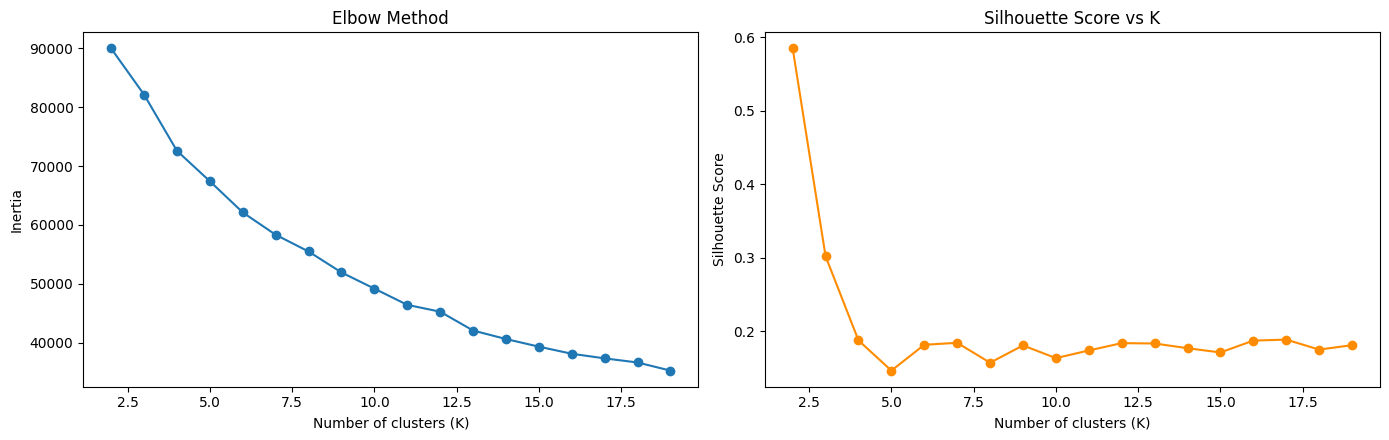

K with the highest silhouette score: 2


In [44]:
k_range = range(2, 20)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=13)
    labels = km.fit_predict(df_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(df_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")

axes[1].plot(list(k_range), silhouettes, marker="o", color="darkorange")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score vs K")

plt.tight_layout()
plt.show()

best_k = list(k_range)[int(numpy.argmax(silhouettes))]
print(f"K with the highest silhouette score: {best_k}")

In [47]:
model = KMeans(n_clusters=3)
model.fit_predict(df_scaled)

array([0, 0, 0, ..., 0, 0, 0], dtype=int32)

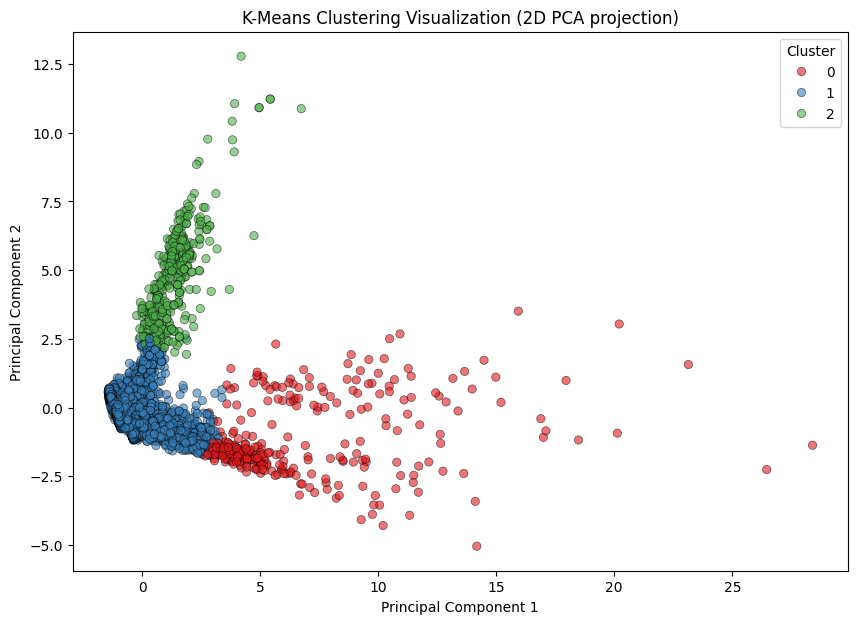

In [48]:
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Predict cluster labels
cluster_labels = model.fit_predict(df_scaled)

# Reduce dimensionality to 2D for visualization
pca = PCA(n_components=2, random_state=13)
pca_features = pca.fit_transform(df_scaled)

# Create a DataFrame for visualization
df_pca = pd.DataFrame(pca_features, columns=['PCA1', 'PCA2'])
df_pca['Cluster'] = cluster_labels

# Plot clusters
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set1',
    data=df_pca,
    alpha=0.6,
    edgecolor='k'
)
plt.title('K-Means Clustering Visualization (2D PCA projection)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

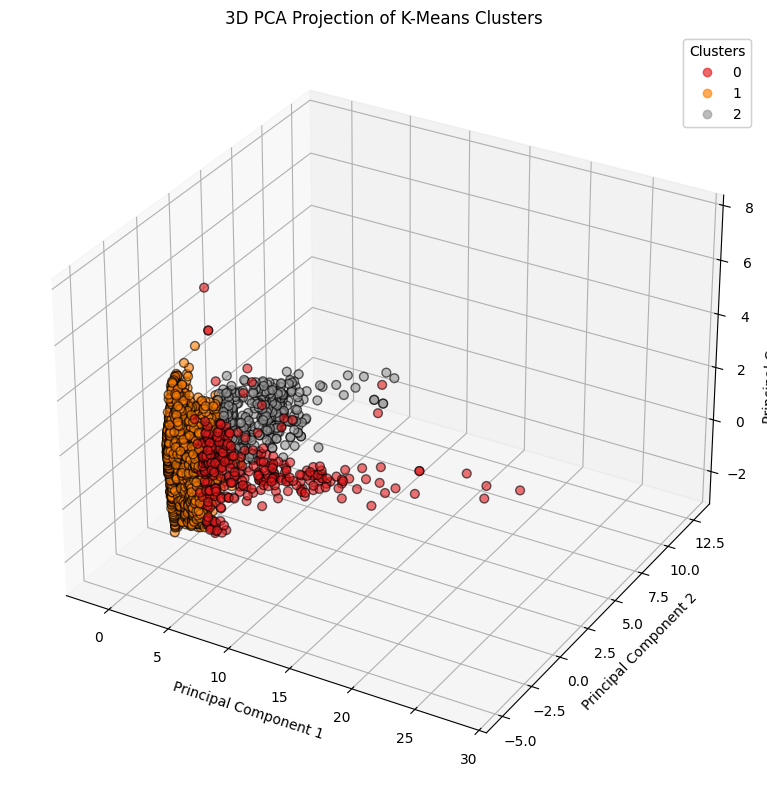

In [49]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Reduce data to 3 components
pca_3d = PCA(n_components=3, random_state=13)
pca_3d_features = pca_3d.fit_transform(df_scaled)

# Create a dataframe for visualization
df_pca_3d = pd.DataFrame(pca_3d_features, columns=['PCA1', 'PCA2', 'PCA3'])
df_pca_3d['Cluster'] = cluster_labels

# Create a 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
scatter = ax.scatter(
    df_pca_3d['PCA1'],
    df_pca_3d['PCA2'],
    df_pca_3d['PCA3'],
    c=df_pca_3d['Cluster'],
    cmap='Set1',
    s=40,
    alpha=0.6,
    edgecolors='k'
)

# Label axes
ax.set_title('3D PCA Projection of K-Means Clusters')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')

# Legend
legend = ax.legend(*scatter.legend_elements(), title="Clusters")
ax.add_artist(legend)

plt.tight_layout()
plt.show()